# Karadeniz Ereğli Hava Kalitesi — Modelleme

`data_preparation.ipynb` ile hazırlanan günlük ölçümleri kullanarak ertesi günün PM2.5 AQI değerini tahmin ediyoruz.

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import TransformedTargetRegressor
from sklearn.ensemble import (
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor,
    RandomForestRegressor,
)
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import (
    GridSearchCV,
    KFold,
    cross_val_score,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor

## Hedef ve değişkenler

Günlük takvimi tamamlayıp her güne bir sonraki günün PM2.5 değerini hedef olarak ekliyoruz. Ertesi güne ait ölçüm yoksa o satırı eğitim verisinden çıkarıyoruz.

In [2]:
df = pd.read_csv("data/processed/eregli_air_quality.csv", parse_dates=["date"])

In [3]:
model_df = (
    df.sort_values("date")
    .drop_duplicates(subset="date")
    .set_index("date")
    .asfreq("D")
)
model_df["target_pm25"] = model_df["pm25"].shift(-1)
model_df = model_df.dropna(subset="target_pm25").reset_index()

feature_columns = ["pm25", "pm10", "o3", "so2", "co"]
X = model_df[feature_columns]
y = model_df["target_pm25"]

print("X:", X.shape)
print("y:", y.shape)
print(X.isna().sum())

X: (2201, 5)
y: (2201,)
pm25     92
pm10    398
o3      366
so2     249
co      123
dtype: int64


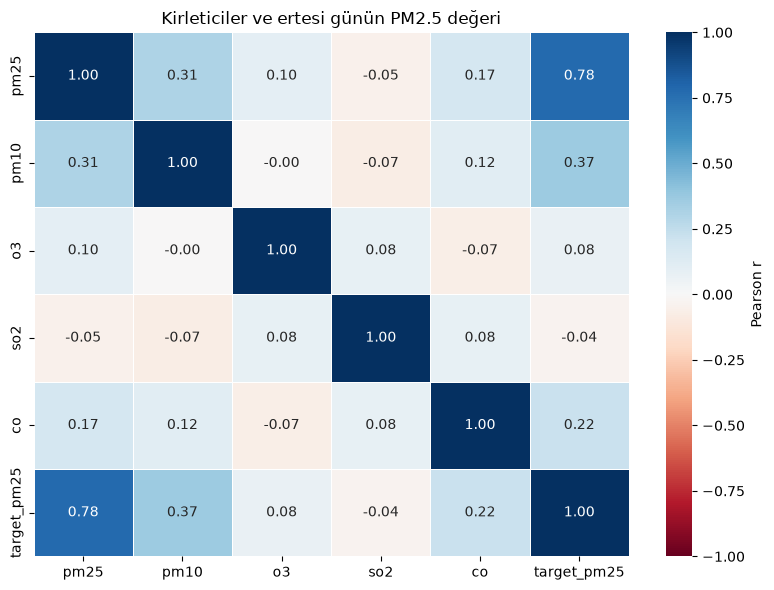

In [4]:
columns = ["pm25", "pm10", "o3", "so2", "co", "target_pm25"]
correlation = model_df[columns].corr(method="pearson")

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="RdBu",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    cbar_kws={"label": "Pearson r"},
)
plt.title("Kirleticiler ve ertesi günün PM2.5 değeri")
plt.tight_layout()
plt.show()

## Eğitim ve test ayrımı

Tarih sırasındaki ilk %80 eğitim, son %20 test için ayrılıyor.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

test_start = model_df.loc[X_test.index[0], "date"] + pd.Timedelta(days=1)
print(f"Eğitim: {len(X_train)} | Test: {len(X_test)} | İlk test hedefi: {test_start:%d.%m.%Y}")

Eğitim: 1760 | Test: 441 | İlk test hedefi: 27.07.2025


## Model karşılaştırması

Modelleri eğitim verisinde 5 katlı çapraz doğrulama ve MAE ile karşılaştırıyoruz. MAE, tahminlerin ortalama kaç AQI puanı saptığını gösterir.

In [6]:
models = {
    "Linear Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("regressor", LinearRegression())
    ]),

    "Ridge": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("regressor", Ridge(alpha=1.0))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("regressor", RandomForestRegressor(
            n_estimators=100,
            n_jobs=-1,
            random_state=42
        ))
    ])
}

In [7]:
kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = {}

for model_name, model in models.items():

    cv_scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=kfold,
        scoring="neg_mean_absolute_error",
        n_jobs=-1
    )

    mae_scores = -cv_scores
    results[model_name] = mae_scores.mean()

    print(
        f"{model_name}: "
        f"Ortalama CV MAE = {mae_scores.mean():.2f} "
        f"(± {mae_scores.std():.2f})"
    )

Linear Regression: Ortalama CV MAE = 14.27 (± 0.79)
Ridge: Ortalama CV MAE = 14.27 (± 0.79)
Random Forest: Ortalama CV MAE = 14.07 (± 0.86)


## Ek model karşılaştırması

In [8]:
comparison_models = {
    "Extra Trees": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("regressor", ExtraTreesRegressor(
            n_estimators=300,
            max_depth=10,
            min_samples_leaf=2,
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("regressor", GradientBoostingRegressor(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=3,
            min_samples_leaf=4,
            random_state=42
        ))
    ]),

    "Histogram Gradient Boosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("regressor", HistGradientBoostingRegressor(
            max_iter=300,
            learning_rate=0.05,
            max_leaf_nodes=31,
            l2_regularization=1.0,
            random_state=42
        ))
    ])
}

In [9]:
for name, model in comparison_models.items():
    scores = cross_val_score(
        model, X_train, y_train, cv=kfold, scoring="neg_mean_absolute_error",
    )
    results[name] = -scores.mean()

## MLP, RBF-SVR ve XGBoost

In [10]:
mlp = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("regressor", MLPRegressor(
        hidden_layer_sizes=(32, 16),
        activation="relu",
        alpha=0.01,
        max_iter=500,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=30,
        random_state=42,
    )),
])

svr = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("regressor", SVR(kernel="rbf", C=10, epsilon=0.15, gamma="scale")),
])

xgboost = XGBRegressor(
    objective="reg:absoluteerror",
    tree_method="hist",
    subsample=0.85,
    colsample_bytree=0.8,
    min_child_weight=4,
    random_state=42,
    n_jobs=2,
)

In [11]:
comparison_models.update({
    "MLP": TransformedTargetRegressor(regressor=mlp, transformer=StandardScaler()),
    "RBF-SVR": TransformedTargetRegressor(regressor=svr, transformer=StandardScaler()),
})

for name in ("MLP", "RBF-SVR"):
    scores = cross_val_score(
        comparison_models[name], X_train, y_train, cv=kfold, scoring="neg_mean_absolute_error",
    )
    results[name] = -scores.mean()

## XGBoost parametre araması

In [12]:
param_grid = {
    "n_estimators": [150, 300],
    "max_depth": [2, 3, 5],
    "learning_rate": [0.03, 0.07],
}

grid_search = GridSearchCV(
    estimator=xgboost,
    param_grid=param_grid,
    cv=kfold,
    scoring="neg_mean_absolute_error",
    n_jobs=1,
)
grid_search.fit(X_train, y_train)
results["XGBoost"] = -grid_search.best_score_

In [13]:
xgboost_parameters = pd.DataFrame({
    "Denenen değerler": {name: ", ".join(map(str, values)) for name, values in param_grid.items()},
    "Seçilen değer": {name: str(value) for name, value in grid_search.best_params_.items()},
}).rename_axis("Parametre")
xgboost_parameters

,Denenen değerler,Seçilen değer
Parametre,,
n_estimators,"150, 300",300
max_depth,"2, 3, 5",5
learning_rate,"0.03, 0.07",0.03


## Final model seçimi

Bütün modelleri eğitim verisindeki ortalama CV MAE'ye göre sıralıyoruz.

In [14]:
candidate_models = {
    **models,
    **comparison_models,
    "XGBoost": grid_search.best_estimator_,
}

comparison_df = (
    pd.Series(results, name="CV MAE")
    .rename_axis("Model")
    .sort_values()
    .to_frame()
)
best_model_name = comparison_df.index[0]
best_model = candidate_models[best_model_name].fit(X_train, y_train)

print(f"Final model: {best_model_name}")
comparison_df.round(2)

Final model: XGBoost


,CV MAE
Model,
XGBoost,13.22
RBF-SVR,13.44
Extra Trees,13.60
Gradient Boosting,13.71
MLP,13.83
Random Forest,14.07
Histogram Gradient Boosting,14.14
Linear Regression,14.27
Ridge,14.27


## Eğitim ve test sonuçları

In [15]:
train_pred = best_model.predict(X_train)
test_pred = best_model.predict(X_test)
train_mae = mean_absolute_error(y_train, train_pred)
test_mae = mean_absolute_error(y_test, test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))
test_r2 = r2_score(y_test, test_pred)

print(f"Eğitim MAE: {train_mae:.2f}")
print(f"Test MAE:   {test_mae:.2f}")
print(f"Test RMSE:  {test_rmse:.2f}")
print(f"Test R²:    {test_r2:.3f}")

Eğitim MAE: 9.84
Test MAE:   10.75
Test RMSE:  15.52
Test R²:    0.621


Basit referans tahmini olarak bugünün PM2.5 değerini ertesi gün için kullanıyoruz.

In [16]:
naive_pred = X_test["pm25"].fillna(X_train["pm25"].median())

naive_mae = mean_absolute_error(y_test, naive_pred)
naive_rmse = np.sqrt(mean_squared_error(y_test, naive_pred))
naive_r2 = r2_score(y_test, naive_pred)

print(f"Naive MAE:  {naive_mae:.2f}")
print(f"Naive RMSE: {naive_rmse:.2f}")
print(f"Naive R²:   {naive_r2:.3f}")

Naive MAE:  11.39
Naive RMSE: 17.10
Naive R²:   0.540


In [17]:
test_comparison = pd.DataFrame(
    [
        (best_model_name, train_mae, test_mae, test_rmse, test_r2),
        ("Basit referans", np.nan, naive_mae, naive_rmse, naive_r2),
    ],
    columns=["Model", "Eğitim MAE", "Test MAE", "Test RMSE", "Test R²"],
).set_index("Model")
test_comparison.round({"Eğitim MAE": 2, "Test MAE": 2, "Test RMSE": 2, "Test R²": 3})

,Eğitim MAE,Test MAE,Test RMSE,Test R²
Model,,,,
XGBoost,9.84,10.75,15.52,0.621
Basit referans,NaN,11.39,17.10,0.540


## Model tahmin eğrileri

Diğer kirleticiler eğitim medyanında sabit. Noktalar gerçek test ölçümleri.

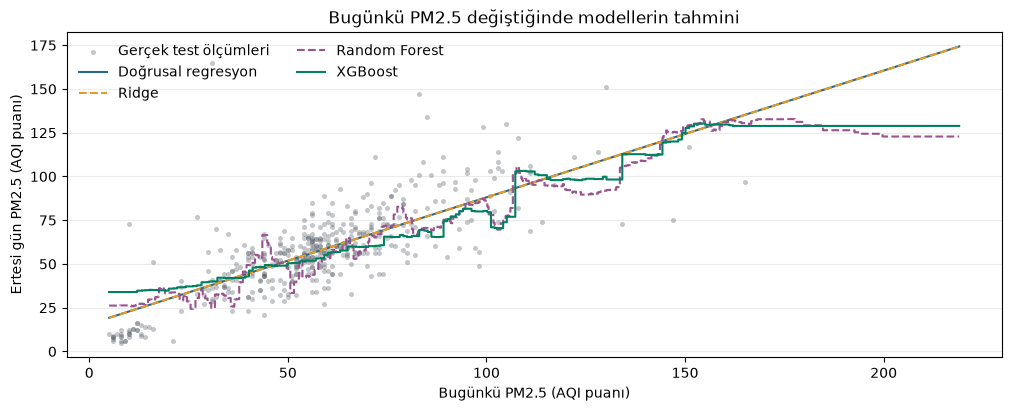

In [18]:
from sklearn.base import clone

pm25_range = np.linspace(X_train["pm25"].min(), X_train["pm25"].max(), 700)
profile = pd.DataFrame({
    column: pm25_range if column == "pm25" else X_train[column].median()
    for column in feature_columns
})

fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
ax.scatter(
    X_test["pm25"], y_test, s=13, alpha=0.32, color="#48505999",
    linewidths=0, label="Gerçek test ölçümleri",
)

for name, label, color, linestyle in (
    ("Linear Regression", "Doğrusal regresyon", "#2A688A", "-"),
    ("Ridge", "Ridge", "#E39B26", "--"),
    ("Random Forest", "Random Forest", "#9A5390", "--"),
    ("XGBoost", "XGBoost", "#008060", "-"),
):
    model = clone(candidate_models[name]).fit(X_train, y_train)
    predictions = model.predict(profile)
    if name in ("Random Forest", "XGBoost"):
        ax.step(pm25_range, predictions, where="post", color=color, linestyle=linestyle, label=label)
    else:
        ax.plot(pm25_range, predictions, color=color, linestyle=linestyle, label=label)

ax.set(
    title="Bugünkü PM2.5 değiştiğinde modellerin tahmini",
    xlabel="Bugünkü PM2.5 (AQI puanı)",
    ylabel="Ertesi gün PM2.5 (AQI puanı)",
)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.legend(loc="upper left", ncol=2, frameon=False)
plt.show()

## Değişken önemi

Bir değişkenin değerleri karıştırıldığında test R² skoru ne kadar düşüyorsa model o değişkene o kadar dayanıyor.

In [19]:
permutation_result = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="r2",
    n_repeats=20,
    random_state=42,
    n_jobs=1
)

importance_df = pd.DataFrame({
    "Değişken": feature_columns,
    "Önem": permutation_result.importances_mean
}).sort_values("Önem", ascending=False)

importance_df

,Değişken,Önem
0,pm25,0.713458
1,pm10,0.195345
4,co,0.023542
2,o3,0.011051
3,so2,-0.003169


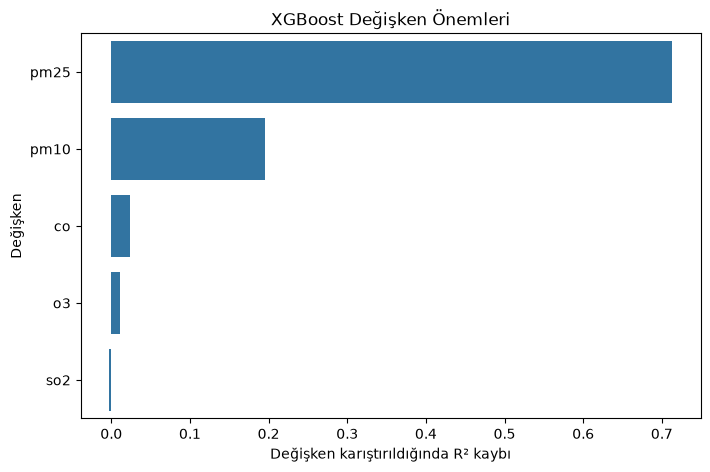

In [20]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=importance_df,
    x="Önem",
    y="Değişken"
)

plt.title(f"{best_model_name} Değişken Önemleri")
plt.xlabel("Değişken karıştırıldığında R² kaybı")
plt.ylabel("Değişken")
plt.show()

c:\Users\ozgur\Desktop\infotech_projeler\AQI_Predictions\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


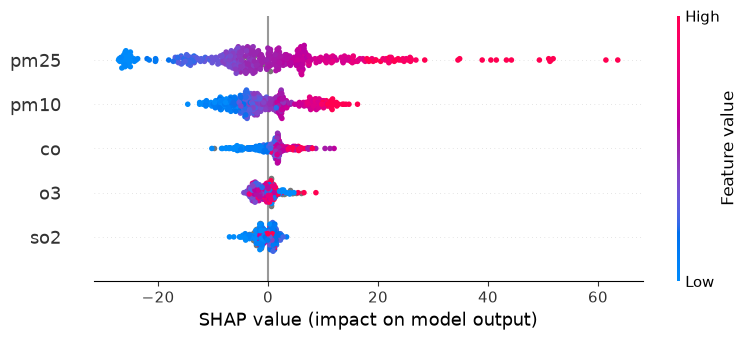

In [21]:
import shap

explainer = shap.Explainer(best_model)
shap_values = explainer(X_test)
shap.summary_plot(shap_values.values, X_test, show=False)
plt.show()

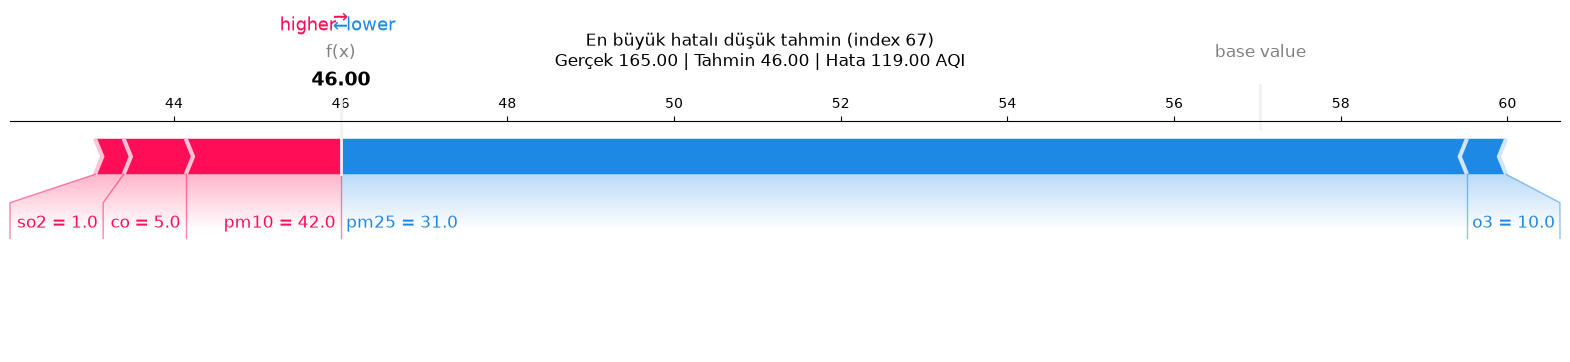

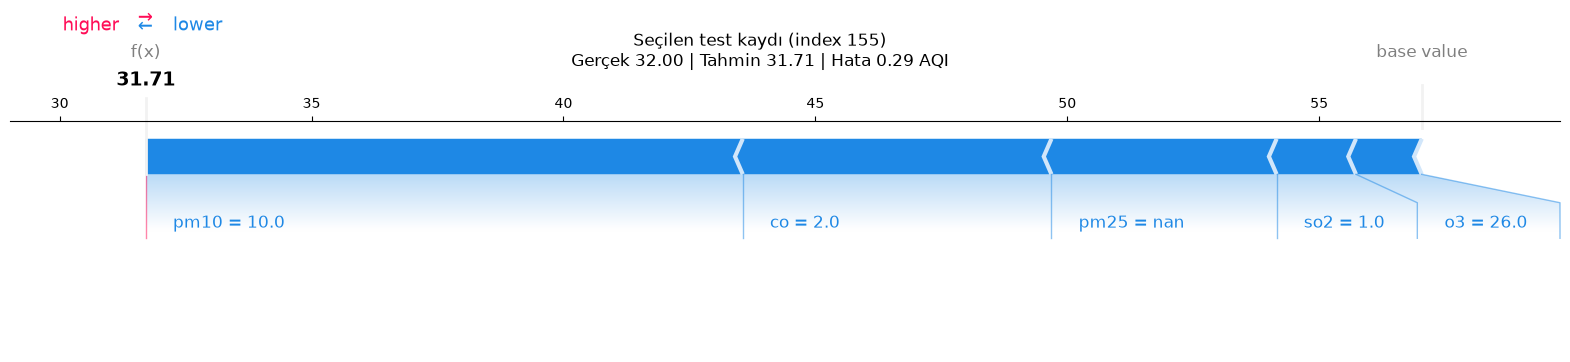

In [22]:
actual = y_test.to_numpy()
predictions = best_model.predict(X_test)
errors = actual - predictions

i = np.argmax(errors)
j = 155

fig = shap.force_plot(
    shap_values.base_values[i],
    shap_values.values[i],
    X_test.iloc[i],
    matplotlib=True,
    show=False,
)
fig.suptitle(
    f"En büyük hatalı düşük tahmin (index {i})\n"
    f"Gerçek {actual[i]:.2f} | Tahmin {predictions[i]:.2f} | "
    f"Hata {abs(errors[i]):.2f} AQI",
    y=1.18,
)
fig = shap.force_plot(
    shap_values.base_values[j],
    shap_values.values[j],
    X_test.iloc[j],
    matplotlib=True,
    show=False,
)
fig.suptitle(
    f"Seçilen test kaydı (index {j})\n"
    f"Gerçek {actual[j]:.2f} | Tahmin {predictions[j]:.2f} | "
    f"Hata {abs(errors[j]):.2f} AQI",
    y=1.18,
)
plt.show()

## Modeli kaydetme

In [23]:
model_directory = Path("./models")
model_directory.mkdir(exist_ok=True)

model_artifact = {
    "model": best_model,
    "model_name": best_model_name,
    "feature_columns": feature_columns,
    "test_mae": test_mae,
    "test_rmse": test_rmse,
    "test_r2": test_r2
}

model_path = model_directory / "pm25_model.joblib"

joblib.dump(model_artifact, model_path)

print(f"Model kaydedildi: {model_path}")

Model kaydedildi: models\pm25_model.joblib
